In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import f1_score, accuracy_score, matthews_corrcoef, ConfusionMatrixDisplay, precision_recall_fscore_support

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif"],
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "mathtext.fontset": "stix",
    "savefig.dpi": 300
})

In [4]:
df = pd.read_csv("networkTraffic.csv", na_values="?")

target = "attack_cat"

X = df.drop(columns=[target, "id"]).copy()
y = df[target].copy()

categorical_features = ["proto", "service", "state"]

numerical_features = [
    column for column in X.columns
    if column not in categorical_features
]

In [58]:
missing_values = pd.DataFrame({
    "count": df.isna().sum(),
    "percentage": (df.isna().mean() * 100).round(4)
})

missing_values = missing_values[missing_values["count"] > 0]

missing_values

,count,percentage
service,141321,54.8451


In [59]:
for column in categorical_features:
    print(f"\n=== {column} ===")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts(dropna=False))


=== proto ===
Unique values: 133
proto
tcp      123041
udp       92701
unas      15599
arp        3846
ospf       3271
          ...  
argus       131
crtp        131
igmp         48
icmp         15
rtp           1
Name: count, Length: 133, dtype: int64

=== service ===
Unique values: 12
service
NaN         141321
dns          68661
http         27011
smtp          6909
ftp-data      5391
ftp           4980
pop3          1528
ssh           1506
dhcp           120
snmp           109
ssl             86
irc             30
radius          21
Name: count, dtype: int64

=== state ===
Unique values: 11
state
FIN    117164
INT    116438
CON     20134
REQ      3833
RST        84
ECO        12
ACC         4
CLO         1
PAR         1
URN         1
no          1
Name: count, dtype: int64


In [60]:
numerical_features = [
    column for column in df.select_dtypes(include=np.number).columns
    if column not in ["id", target]
]

numeric_ranges = pd.DataFrame({
    "min": df[numerical_features].min(),
    "max": df[numerical_features].max()
})

numeric_ranges["range"] = numeric_ranges["max"] - numeric_ranges["min"]

numeric_ranges.sort_values("range", ascending=False)

,min,max,range
sload,0.0,5.988000e+09,5.988000e+09
stcpb,0.0,4.294959e+09,4.294959e+09
dtcpb,0.0,4.294882e+09,4.294882e+09
dload,0.0,2.242273e+07,2.242273e+07
dbytes,0.0,1.465753e+07,1.465753e+07
sbytes,24.0,1.435577e+07,1.435575e+07
response_body_len,0.0,6.558056e+06,6.558056e+06
sjit,0.0,1.483831e+06,1.483831e+06
rate,0.0,1.000000e+06,1.000000e+06
djit,0.0,4.631992e+05,4.631992e+05


In [61]:
outlier_results = []

for column in numerical_features:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_results.append({
        "feature": column,
        "outlier_count": outlier_count,
        "outlier_percentage": outlier_count / len(df) * 100
    })

outlier_table = pd.DataFrame(outlier_results)

outlier_table.sort_values(
    "outlier_percentage",
    ascending=False
).round(4)

,feature,outlier_count,outlier_percentage
9,dload,57556,22.3368
30,ct_src_dport_ltm,49014,19.0218
31,ct_dst_sport_ltm,48244,18.7230
32,ct_dst_src_ltm,43419,16.8504
29,ct_dst_ltm,42388,16.4503
4,dbytes,40024,15.5329
11,dloss,39660,15.3916
1,spkts,34871,13.5330
37,ct_srv_dst,34048,13.2136
24,dmean,33189,12.8803


In [62]:
correlation_matrix = df[numerical_features].corr().abs()

strong_correlations = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        correlation = correlation_matrix.iloc[i, j]

        if correlation >= 0.90:
            strong_correlations.append({
                "feature_1": correlation_matrix.columns[i],
                "feature_2": correlation_matrix.columns[j],
                "correlation": correlation
            })

strong_correlations = pd.DataFrame(strong_correlations)

strong_correlations.sort_values(
    "correlation",
    ascending=False
).round(4)

,feature_1,feature_2,correlation
17,is_ftp_login,ct_ftp_cmd,0.9989
5,dbytes,dloss,0.9967
4,sbytes,sloss,0.9958
7,swin,dwin,0.9805
3,dpkts,dloss,0.9796
11,ct_srv_src,ct_srv_dst,0.9795
2,dpkts,dbytes,0.9734
1,spkts,sloss,0.9719
0,spkts,sbytes,0.9644
12,ct_dst_ltm,ct_src_dport_ltm,0.9615


In [63]:
predictors = df.drop(columns=["id", target])

predictor_hash = pd.util.hash_pandas_object(
    predictors,
    index=False
)

duplicate_groups = pd.DataFrame({
    "group": predictor_hash,
    "label": df[target]
}).groupby("group").agg(
    group_size=("label", "size"),
    label_count=("label", "nunique")
)

duplicate_only = duplicate_groups[
    duplicate_groups["group_size"] > 1
]

same_label_duplicates = duplicate_only[
    duplicate_only["label_count"] == 1
]

conflicting_duplicates = duplicate_only[
    duplicate_only["label_count"] > 1
]

print("Unique predictor patterns:", predictor_hash.nunique())
print("Duplicate predictor groups:", len(duplicate_only))
print("Rows in duplicate groups:", duplicate_only["group_size"].sum())

print("\nSame-label duplicate groups:", len(same_label_duplicates))
print("Rows in same-label duplicate groups:", same_label_duplicates["group_size"].sum())

print("\nConflicting duplicate groups:", len(conflicting_duplicates))
print("Rows in conflicting duplicate groups:", conflicting_duplicates["group_size"].sum())

Unique predictor patterns: 153684
Duplicate predictor groups: 15712
Rows in duplicate groups: 119701

Same-label duplicate groups: 13267
Rows in same-label duplicate groups: 79301

Conflicting duplicate groups: 2445
Rows in conflicting duplicate groups: 40400


In [74]:
class_distribution = pd.DataFrame({
    "count": df[target].value_counts().sort_index(),
})

class_distribution

,count
attack_cat,
0,93000
1,13987
2,2329
3,16353
4,44525
5,2677
6,24246
7,174
8,1511


In [5]:
correlated_features_to_remove = ["sloss", "dloss", "is_ftp_login"]

knn_numerical_features = [
    column for column in numerical_features
    if column not in correlated_features_to_remove
]

In [6]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

numerical_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

knn_preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numerical", numerical_pipeline, knn_numerical_features)
])

knn_pipeline = Pipeline([
    ("preprocessor", knn_preprocessor),
    ("model", KNeighborsClassifier())
])

tree_preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numerical", "passthrough", numerical_features)
])

tree_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", DecisionTreeClassifier(random_state=22))
])

In [54]:
knn_outer_results = pd.DataFrame(outer_results)

display(knn_outer_results.round(4))

knn_outer_results.round(4).to_csv(
    "knn_outer_results.csv",
    index=False
)

knn_outer_results.round(4).to_latex(
    "knn_outer_results.tex",
    index=False
)

,fold,macro_f1,mcc,accuracy
0,1,0.4919,0.7243,0.7877
1,2,0.5208,0.7438,0.8037
2,3,0.5426,0.7477,0.8065
3,4,0.5241,0.7467,0.8057
4,5,0.5109,0.7413,0.8017


In [55]:
knn_best_parameters = pd.DataFrame(best_parameters)

display(knn_best_parameters.round(4))

knn_best_parameters.round(4).to_csv(
    "knn_best_parameters.csv",
    index=False
)

knn_best_parameters.round(4).to_latex(
    "knn_best_parameters.tex",
    index=False
)

,fold,model__n_neighbors,model__p,model__weights,preprocessor__numerical__scaler
0,1,5,1,distance,RobustScaler()
1,2,10,1,distance,RobustScaler()
2,3,10,1,distance,RobustScaler()
3,4,10,1,distance,RobustScaler()
4,5,10,1,distance,RobustScaler()


In [20]:
tree_group_ids = pd.util.hash_pandas_object(X, index=False)

tree_outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=22)
tree_inner_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=10)

tree_param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_leaf": [1, 5, 20],
    "model__class_weight": [None, "balanced"]
}

tree_scoring = {
    "macro_f1": "f1_macro",
    "mcc": "matthews_corrcoef",
    "accuracy": "accuracy"
}

tree_outer_results = []
tree_best_parameters = []
tree_oof_predictions = np.empty(len(y), dtype=y.dtype)

for tree_fold, (tree_train_index, tree_test_index) in enumerate(
    tree_outer_cv.split(X, y, groups=tree_group_ids),
    start=1
):
    print(f"\nOuter Fold {tree_fold}/5")

    tree_X_train = X.iloc[tree_train_index]
    tree_X_test = X.iloc[tree_test_index]
    tree_y_train = y.iloc[tree_train_index]
    tree_y_test = y.iloc[tree_test_index]
    tree_groups_train = tree_group_ids.iloc[tree_train_index]

    tree_search = GridSearchCV(
        estimator=tree_pipeline,
        param_grid=tree_param_grid,
        scoring=tree_scoring,
        refit="macro_f1",
        cv=tree_inner_cv,
        n_jobs=4,
        verbose=10
    )

    tree_search.fit(
        tree_X_train,
        tree_y_train,
        groups=tree_groups_train
    )

    tree_predictions = tree_search.best_estimator_.predict(tree_X_test)
    tree_oof_predictions[tree_test_index] = tree_predictions

    tree_outer_results.append({
        "fold": tree_fold,
        "macro_f1": f1_score(tree_y_test, tree_predictions, average="macro"),
        "mcc": matthews_corrcoef(tree_y_test, tree_predictions),
        "accuracy": accuracy_score(tree_y_test, tree_predictions)
    })

    tree_best_parameters.append({
        "fold": tree_fold,
        **tree_search.best_params_
    })

    print("Best Parameters:", tree_search.best_params_)


Outer Fold 1/5
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 20, 'model__min_samples_leaf': 5}

Outer Fold 2/5
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 20, 'model__min_samples_leaf': 1}

Outer Fold 3/5
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 20, 'model__min_samples_leaf': 1}

Outer Fold 4/5
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 20, 'model__min_samples_leaf': 1}

Outer Fold 5/5
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters: {'model__class_weight': 'balanced', 'mode

In [49]:
tree_outer_results_df = pd.DataFrame(tree_outer_results)
display(tree_outer_results_df.round(4))

tree_outer_results_df.round(4).to_csv(
    "tree_outer_results.csv",
    index=False
)

tree_outer_results_df.round(4).to_latex(
    "tree_outer_results.tex",
    index=False
)

,fold,macro_f1,mcc,accuracy
0,1,0.5963,0.7151,0.7680
1,2,0.6068,0.7178,0.7716
2,3,0.5958,0.7163,0.7693
3,4,0.5952,0.7201,0.7732
4,5,0.5892,0.7140,0.7679


In [52]:
tree_best_parameters = pd.DataFrame(tree_best_parameters)
display(tree_best_parameters.round(4))

tree_best_parameters.round(4).to_csv(
    "tree_best_parameters.csv",
    index=False
)

tree_best_parameters.round(4).to_latex(
    "tree_best_parameters.tex",
    index=False
)

,fold,model__class_weight,model__criterion,model__max_depth,model__min_samples_leaf
0,1,balanced,entropy,20,5
1,2,balanced,entropy,20,1
2,3,balanced,entropy,20,1
3,4,balanced,entropy,20,1
4,5,balanced,entropy,20,1


<Figure size 1000x800 with 0 Axes>

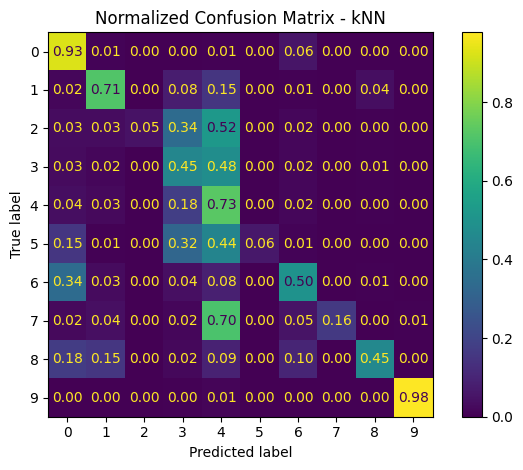

In [75]:
plt.figure(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y,
    oof_predictions,
    normalize="true",
    values_format=".2f"
)

plt.title("Normalized Confusion Matrix - kNN")
plt.tight_layout()
plt.savefig("knn_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 1000x800 with 0 Axes>

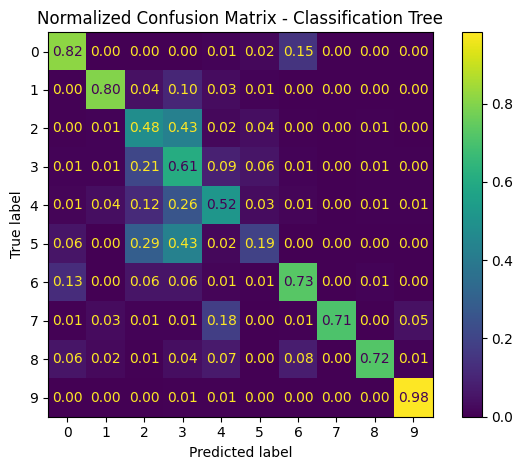

In [76]:
plt.figure(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y,
    tree_oof_predictions,
    normalize="true",
    values_format=".2f"
)

plt.title("Normalized Confusion Matrix - Classification Tree")
plt.tight_layout()
plt.savefig("tree_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [77]:
class_labels = np.sort(y.unique())

knn_precision, knn_recall, knn_f1, knn_support = precision_recall_fscore_support(
    y,
    oof_predictions,
    labels=class_labels,
    zero_division=0
)

tree_precision, tree_recall, tree_f1, tree_support = precision_recall_fscore_support(
    y,
    tree_oof_predictions,
    labels=class_labels,
    zero_division=0
)

per_class_results = pd.DataFrame({
    "Class": class_labels,
    "Support": knn_support,
    "kNN Precision": knn_precision,
    "kNN Recall": knn_recall,
    "kNN F1": knn_f1,
    "Tree Precision": tree_precision,
    "Tree Recall": tree_recall,
    "Tree F1": tree_f1
})

display(per_class_results.round(4))

per_class_results.round(4).to_csv(
    "per_class_results.csv",
    index=False
)

per_class_results.round(4).to_latex(
    "per_class_results.tex",
    index=False
)

,Class,Support,kNN Precision,kNN Recall,kNN F1,Tree Precision,Tree Recall,Tree F1
0,0,93000,0.8829,0.9251,0.9035,0.9485,0.8165,0.8776
1,1,13987,0.7495,0.7107,0.7295,0.8469,0.7989,0.8222
2,2,2329,0.6085,0.0494,0.0913,0.0890,0.4826,0.1502
3,3,16353,0.3755,0.4497,0.4092,0.3679,0.6085,0.4586
4,4,44525,0.6692,0.7284,0.6975,0.8627,0.5176,0.6470
5,5,2677,0.5943,0.0624,0.1129,0.0983,0.1924,0.1301
6,6,24246,0.6432,0.4995,0.5623,0.5462,0.7269,0.6237
7,7,174,0.5833,0.1609,0.2523,0.5885,0.7069,0.6423
8,8,1511,0.3834,0.4547,0.4160,0.5584,0.7181,0.6283
9,9,58871,0.9959,0.9774,0.9865,0.9908,0.9825,0.9866


In [ ]:
# Assignment 4 - Ensemble Learning

In [ ]:
## Random Forest Setup

In [8]:
from sklearn.ensemble import RandomForestClassifier

forest_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", RandomForestClassifier(
        criterion="entropy",
        max_depth=20,
        min_samples_leaf=1,
        n_estimators=50,
        max_features="sqrt",
        class_weight="balanced",
        bootstrap=True,
        random_state=22,
        n_jobs=1
    ))
])


In [9]:
## Cross Validation

In [10]:

forest_group_ids = pd.util.hash_pandas_object(X, index=False)

forest_outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=22
)

forest_inner_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=10
)


In [11]:

for fold, (train_index, test_index) in enumerate(forest_outer_cv.split(X, y, groups=forest_group_ids), start=1):
    train_groups = set(forest_group_ids.iloc[train_index])
    test_groups = set(forest_group_ids.iloc[test_index])

    overlap = len(train_groups.intersection(test_groups))

    print(f"Fold {fold}")
    print(f"Training instances: {len(train_index)}")
    print(f"Testing instances: {len(test_index)}")
    print(f"Overlapping groups: {overlap}")
    print()


Fold 1
Training instances: 206138
Testing instances: 51535
Overlapping groups: 0

Fold 2
Training instances: 206138
Testing instances: 51535
Overlapping groups: 0

Fold 3
Training instances: 206139
Testing instances: 51534
Overlapping groups: 0

Fold 4
Training instances: 206138
Testing instances: 51535
Overlapping groups: 0

Fold 5
Training instances: 206139
Testing instances: 51534
Overlapping groups: 0



In [12]:
# Testing different number of trees

In [15]:

from pathlib import Path
from time import perf_counter
from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_class_weight

tree_counts = [1, 5, 10, 25, 50, 100, 200, 400]

results_file = Path("forest_trees_warmstart.csv")
forest_trees_results = []

if results_file.exists():
    forest_trees_results = pd.read_csv(results_file).to_dict("records")

max_outer_folds = 5
max_inner_folds = 5

for outer_fold, (train_index, test_index) in enumerate(forest_outer_cv.split(X, y, groups=forest_group_ids), start=1):
    if outer_fold > max_outer_folds:
        break

    print(f"\nOuter Fold {outer_fold}/5", flush=True)

    X_outer = X.iloc[train_index]
    y_outer = y.iloc[train_index]
    groups_outer = forest_group_ids.iloc[train_index]

    for inner_fold, (inner_train_index, inner_val_index) in enumerate(forest_inner_cv.split(X_outer, y_outer, groups=groups_outer), start=1):
        if inner_fold > max_inner_folds:
            break

        completed_counts = []

        for result in forest_trees_results:
            if result["outer_fold"] == outer_fold and result["inner_fold"] == inner_fold:
                completed_counts.append(int(result["n_estimators"]))

        completed = True

        for n_trees in tree_counts:
            if n_trees not in completed_counts:
                completed = False

        if completed:
            print(f"Inner Fold {inner_fold} already completed.")
            continue

        print(f"Inner Fold {inner_fold}/5", flush=True)

        X_train = X_outer.iloc[inner_train_index]
        X_val = X_outer.iloc[inner_val_index]

        y_train = y_outer.iloc[inner_train_index]
        y_val = y_outer.iloc[inner_val_index]

        preprocessor = clone(tree_preprocessor)

        X_train_processed = preprocessor.fit_transform(X_train)
        X_val_processed = preprocessor.transform(X_val)

        classes = np.unique(y_train)
        weights = compute_class_weight("balanced", classes=classes, y=y_train)

        class_weights = {}

        for i in range(len(classes)):
            class_weights[classes[i]] = weights[i]

        forest = clone(forest_pipeline.named_steps["model"])
        forest.set_params(warm_start=True, n_jobs=2, class_weight=class_weights)

        total_fit_time = 0
        fold_results = []

        for n_trees in tree_counts:
            forest.set_params(n_estimators=n_trees)

            start = perf_counter()
            forest.fit(X_train_processed, y_train)
            fit_time = perf_counter() - start

            total_fit_time += fit_time

            predictions = forest.predict(X_val_processed)
            macro_f1 = f1_score(y_val, predictions, average="macro")

            fold_results.append({
                "outer_fold": outer_fold,
                "inner_fold": inner_fold,
                "n_estimators": n_trees,
                "validation_f1": macro_f1,
                "fit_time": total_fit_time
            })

            print(f"Trees: {n_trees} | Macro F1: {macro_f1:.4f} | Time: {total_fit_time:.1f}s", flush=True)

        forest_trees_results = [
            result for result in forest_trees_results
            if not (result["outer_fold"] == outer_fold and result["inner_fold"] == inner_fold)
        ]

        forest_trees_results.extend(fold_results)

        pd.DataFrame(forest_trees_results).to_csv(results_file, index=False)

print("\nExperiment 1 completed.")

forest_trees_results_df = pd.DataFrame(forest_trees_results)

forest_trees_summary = forest_trees_results_df.groupby("n_estimators")[
    ["validation_f1", "fit_time"]
].agg(["mean", "std"])

display(forest_trees_summary.round(4))



Outer Fold 1/5
Inner Fold 1 already completed.
Inner Fold 2 already completed.
Inner Fold 3 already completed.
Inner Fold 4 already completed.
Inner Fold 5 already completed.

Outer Fold 2/5
Inner Fold 1 already completed.
Inner Fold 2 already completed.
Inner Fold 3 already completed.
Inner Fold 4 already completed.
Inner Fold 5 already completed.

Outer Fold 3/5
Inner Fold 1 already completed.
Inner Fold 2 already completed.
Inner Fold 3 already completed.
Inner Fold 4 already completed.
Inner Fold 5 already completed.

Outer Fold 4/5
Inner Fold 1 already completed.
Inner Fold 2 already completed.
Inner Fold 3 already completed.
Inner Fold 4 already completed.
Inner Fold 5 already completed.

Outer Fold 5/5
Inner Fold 1 already completed.
Inner Fold 2 already completed.
Inner Fold 3 already completed.
Inner Fold 4 already completed.
Inner Fold 5 already completed.

Experiment 1 completed.


validation_f1          fit_time         
                      mean     std      mean      std
n_estimators                                         
1                   0.5045  0.0172    2.2239   0.2617
5                   0.5455  0.0082    7.0744   0.5468
10                  0.5591  0.0084   13.7754   1.0187
25                  0.5708  0.0101   31.5689   1.7595
50                  0.5751  0.0103   60.8090   2.4765
100                 0.5809  0.0102  119.0693   4.5762
200                 0.5821  0.0094  235.1919   8.3345
400                 0.5837  0.0088  468.7642  18.3737

Number of Trees - Performance


,validation_f1,validation_std,fit_time
n_estimators,,,
1,0.5045,0.0172,2.2239
5,0.5455,0.0082,7.0744
10,0.5591,0.0084,13.7754
25,0.5708,0.0101,31.5689
50,0.5751,0.0103,60.8090
100,0.5809,0.0102,119.0693
200,0.5821,0.0094,235.1919
400,0.5837,0.0088,468.7642
800,0.5797,0.0090,967.2747


Best Configuration per Completed Outer Fold


,outer_fold,n_estimators,macro_f1
0,1,400,0.5818
1,2,400,0.5783
2,3,400,0.5911
3,4,400,0.5850
4,5,400,0.5821


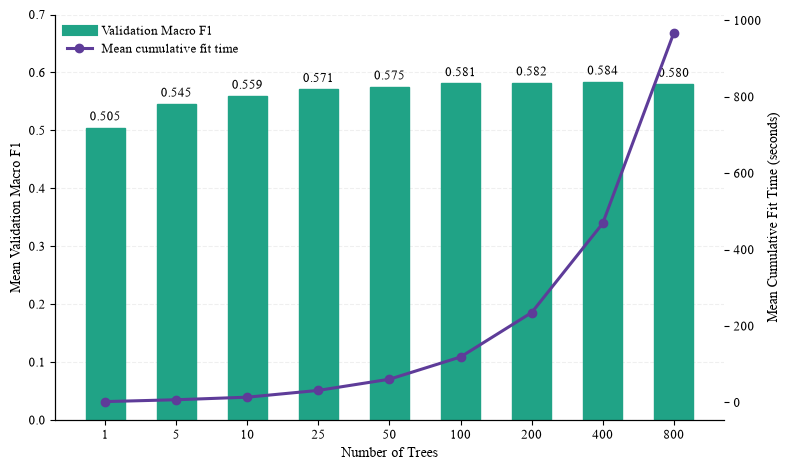

In [63]:

forest_trees_results_df = pd.read_csv("forest_trees_warmstart.csv")

forest_trees_summary = forest_trees_results_df.groupby("n_estimators").agg(
    validation_f1=("validation_f1", "mean"),
    validation_std=("validation_f1", "std"),
    fit_time=("fit_time", "mean")
)

print("Number of Trees - Performance")
display(forest_trees_summary.round(4))

forest_trees_best = []

for outer_fold, results in forest_trees_results_df.groupby("outer_fold"):
    if results["inner_fold"].nunique() < 5:
        continue

    scores = results.groupby("n_estimators")["validation_f1"].mean()
    best_trees = scores.idxmax()

    forest_trees_best.append({
        "outer_fold": outer_fold,
        "n_estimators": best_trees,
        "macro_f1": scores.loc[best_trees]
    })

print("Best Configuration per Completed Outer Fold")

if forest_trees_best:
    display(pd.DataFrame(forest_trees_best).round(4))
else:
    print("No outer folds completed yet.")

tree_values = forest_trees_summary.index.tolist()
tree_f1 = forest_trees_summary["validation_f1"].tolist()
tree_time = forest_trees_summary["fit_time"].tolist()

x = np.arange(len(tree_values))

cmap = plt.get_cmap("viridis")
bar_color = cmap(0.58)
line_color = "#5E3C99"

fig, ax1 = plt.subplots(figsize=(8, 4.8))

bars = ax1.bar(x, tree_f1, width=0.55, color=bar_color, edgecolor=bar_color)

for i in range(len(tree_values)):
    ax1.text(
        x[i],
        tree_f1[i] + 0.008,
        f"{tree_f1[i]:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax1.set_xlabel("Number of Trees")
ax1.set_ylabel("Mean Validation Macro F1")
ax1.set_xticks(x)
ax1.set_xticklabels(tree_values)
ax1.set_ylim(0, 0.7)
ax1.grid(axis="y", linestyle="--", alpha=0.2)
ax1.set_axisbelow(True)

ax2 = ax1.twinx()
ax2.plot(x, tree_time, color=line_color, marker="o", linewidth=2.2, markersize=6)
ax2.set_ylabel("Mean Cumulative Fit Time (seconds)")

bar_proxy = plt.Line2D([0], [0], color=bar_color, linewidth=8)
line_proxy = plt.Line2D([0], [0], color=line_color, marker="o", linewidth=2.2)

ax1.legend(
    [bar_proxy, line_proxy],
    ["Validation Macro F1", "Mean cumulative fit time"],
    loc="upper left",
    frameon=False,
    fontsize=9
)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax2.spines["top"].set_visible(False)

fig.tight_layout()
fig.savefig("forest_trees_performance.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
feature_values = ["log2", "sqrt", 0.25, 0.4, 0.6]

results_file = Path("forest_features_100_results.csv")
forest_features_results = []

if results_file.exists():
    forest_features_results = pd.read_csv(results_file).to_dict("records")

max_outer_folds = 5
max_inner_folds = 5

for outer_fold, (train_index, test_index) in enumerate(forest_outer_cv.split(X, y, groups=forest_group_ids), start=1):
    if outer_fold > max_outer_folds:
        break

    print(f"\nOuter Fold {outer_fold}/5", flush=True)

    X_outer = X.iloc[train_index]
    y_outer = y.iloc[train_index]
    groups_outer = forest_group_ids.iloc[train_index]

    for inner_fold, (inner_train_index, inner_val_index) in enumerate(forest_inner_cv.split(X_outer, y_outer, groups=groups_outer), start=1):
        if inner_fold > max_inner_folds:
            break

        completed_features = []

        for result in forest_features_results:
            if result["outer_fold"] == outer_fold and result["inner_fold"] == inner_fold:
                completed_features.append(str(result["max_features"]))

        completed = True

        for max_features in feature_values:
            if str(max_features) not in completed_features:
                completed = False

        if completed:
            print(f"Inner Fold {inner_fold} already completed.")
            continue

        print(f"Inner Fold {inner_fold}/5", flush=True)

        X_train = X_outer.iloc[inner_train_index]
        X_val = X_outer.iloc[inner_val_index]

        y_train = y_outer.iloc[inner_train_index]
        y_val = y_outer.iloc[inner_val_index]

        preprocessor = clone(tree_preprocessor)

        X_train_processed = preprocessor.fit_transform(X_train)
        X_val_processed = preprocessor.transform(X_val)

        for max_features in feature_values:
            if str(max_features) in completed_features:
                continue

            forest = clone(forest_pipeline.named_steps["model"])
            forest.set_params(n_estimators=100, max_features=max_features, class_weight="balanced", warm_start=False, n_jobs=2)

            start = perf_counter()
            forest.fit(X_train_processed, y_train)
            fit_time = perf_counter() - start

            predictions = forest.predict(X_val_processed)
            macro_f1 = f1_score(y_val, predictions, average="macro")

            forest_features_results.append({
                "outer_fold": outer_fold,
                "inner_fold": inner_fold,
                "max_features": str(max_features),
                "validation_f1": macro_f1,
                "fit_time": fit_time
            })

            pd.DataFrame(forest_features_results).to_csv(results_file, index=False)

            print(f"Features: {max_features} | Macro F1: {macro_f1:.4f} | Time: {fit_time:.1f}s", flush=True)

forest_features_results_df = pd.DataFrame(forest_features_results)

forest_features_summary = forest_features_results_df.groupby("max_features").agg(
    validation_f1_mean=("validation_f1", "mean"),
    validation_f1_std=("validation_f1", "std"),
    fit_time_mean=("fit_time", "mean"),
    fit_time_std=("fit_time", "std"),
    completed_fits=("validation_f1", "count")
)

display(forest_features_summary.round(4))


Outer Fold 1/5
Inner Fold 1/5
Features: 0.4 | Macro F1: 0.6258 | Time: 215.4s
Features: 0.6 | Macro F1: 0.6219 | Time: 272.7s
Inner Fold 2/5
Features: 0.4 | Macro F1: 0.6214 | Time: 243.8s
Features: 0.6 | Macro F1: 0.6162 | Time: 311.6s
Inner Fold 3/5
Features: 0.4 | Macro F1: 0.6221 | Time: 220.9s
Features: 0.6 | Macro F1: 0.6226 | Time: 264.9s
Inner Fold 4/5
Features: 0.4 | Macro F1: 0.6191 | Time: 207.9s
Features: 0.6 | Macro F1: 0.6156 | Time: 270.8s
Inner Fold 5/5
Features: 0.4 | Macro F1: 0.6181 | Time: 213.2s
Features: 0.6 | Macro F1: 0.6202 | Time: 306.0s

Outer Fold 2/5
Inner Fold 1/5
Features: 0.4 | Macro F1: 0.6164 | Time: 228.6s
Features: 0.6 | Macro F1: 0.6165 | Time: 272.6s
Inner Fold 2/5
Features: 0.4 | Macro F1: 0.6282 | Time: 204.2s
Features: 0.6 | Macro F1: 0.6295 | Time: 263.2s
Inner Fold 3/5
Features: 0.4 | Macro F1: 0.6189 | Time: 214.3s
Features: 0.6 | Macro F1: 0.6210 | Time: 285.3s
Inner Fold 4/5
Features: 0.4 | Macro F1: 0.6285 | Time: 224.0s
Features: 0.6 | M

,validation_f1_mean,validation_f1_std,fit_time_mean,fit_time_std,completed_fits
max_features,,,,,
0.25,0.6175,0.0054,183.8557,12.8385,25
0.4,0.6226,0.0047,218.7686,9.2745,25
0.6,0.6226,0.0049,277.9409,14.5861,25
log2,0.5463,0.0082,98.0737,6.5234,25
sqrt,0.5809,0.0102,127.5574,8.7933,25


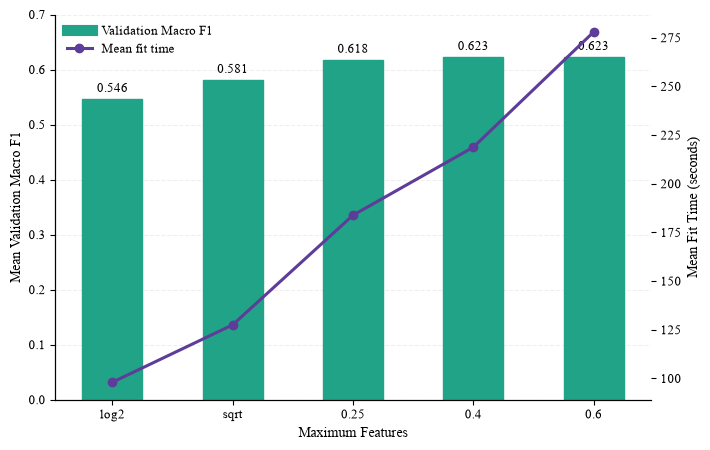

In [64]:
feature_results = pd.read_csv("forest_features_100_results.csv", keep_default_na=False)

feature_values = ["log2", "sqrt", "0.25", "0.4", "0.6"]

feature_f1 = []
feature_time = []

for value in feature_values:
    results = feature_results[feature_results["max_features"].astype(str) == value]
    feature_f1.append(results["validation_f1"].mean())
    feature_time.append(results["fit_time"].mean())

x = np.arange(len(feature_values))

cmap = plt.get_cmap("viridis")
bar_color = cmap(0.58)
line_color = "#5E3C99"

fig, ax1 = plt.subplots(figsize=(7.2, 4.6))

bars = ax1.bar(x, feature_f1, width=0.5, color=bar_color, edgecolor=bar_color)

for i in range(len(feature_values)):
    ax1.text(
        x[i],
        feature_f1[i] + 0.008,
        f"{feature_f1[i]:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax1.set_xlabel("Maximum Features")
ax1.set_ylabel("Mean Validation Macro F1")
ax1.set_xticks(x)
ax1.set_xticklabels(feature_values)
ax1.set_ylim(0, 0.7)
ax1.grid(axis="y", linestyle="--", alpha=0.2)
ax1.set_axisbelow(True)

ax2 = ax1.twinx()
ax2.plot(x, feature_time, color=line_color, marker="o", linewidth=2.2, markersize=6)
ax2.set_ylabel("Mean Fit Time (seconds)")

bar_proxy = plt.Line2D([0], [0], color=bar_color, linewidth=8)
line_proxy = plt.Line2D([0], [0], color=line_color, marker="o", linewidth=2.2)

ax1.legend(
    [bar_proxy, line_proxy],
    ["Validation Macro F1", "Mean fit time"],
    loc="upper left",
    frameon=False,
    fontsize=9
)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax2.spines["top"].set_visible(False)

fig.tight_layout()
fig.savefig("forest_features_performance.png", dpi=300, bbox_inches="tight")
plt.show()

In [25]:
depth_values = [10, 20, 30, None]

results_file = Path("forest_depth_results.csv")
forest_depth_results = []

if results_file.exists():
    forest_depth_results = pd.read_csv(results_file, keep_default_na=False).to_dict("records")

features_file = Path("forest_features_100_results.csv")

if features_file.exists() and forest_pipeline.named_steps["model"].max_depth == 20:
    previous_results = pd.read_csv(features_file)

    for i in range(len(previous_results)):
        result = previous_results.iloc[i]

        if str(result["max_features"]) != "0.4":
            continue

        completed = False

        for existing in forest_depth_results:
            if existing["outer_fold"] == result["outer_fold"] and existing["inner_fold"] == result["inner_fold"] and str(existing["max_depth"]) == "20":
                completed = True
                break

        if not completed:
            forest_depth_results.append({
                "outer_fold": int(result["outer_fold"]),
                "inner_fold": int(result["inner_fold"]),
                "max_depth": "20",
                "validation_f1": result["validation_f1"],
                "fit_time": result["fit_time"]
            })

    pd.DataFrame(forest_depth_results).to_csv(results_file, index=False)

max_outer_folds = 5
max_inner_folds = 5

for outer_fold, (train_index, test_index) in enumerate(forest_outer_cv.split(X, y, groups=forest_group_ids), start=1):
    if outer_fold > max_outer_folds:
        break

    print(f"\nOuter Fold {outer_fold}/5", flush=True)

    X_outer = X.iloc[train_index]
    y_outer = y.iloc[train_index]
    groups_outer = forest_group_ids.iloc[train_index]

    for inner_fold, (inner_train_index, inner_val_index) in enumerate(forest_inner_cv.split(X_outer, y_outer, groups=groups_outer), start=1):
        if inner_fold > max_inner_folds:
            break

        completed_depths = []

        for result in forest_depth_results:
            if result["outer_fold"] == outer_fold and result["inner_fold"] == inner_fold:
                completed_depths.append(str(result["max_depth"]))

        completed = True

        for max_depth in depth_values:
            depth_label = str(max_depth)

            if depth_label not in completed_depths:
                completed = False

        if completed:
            print(f"Inner Fold {inner_fold} already completed.")
            continue

        print(f"Inner Fold {inner_fold}/5", flush=True)

        X_train = X_outer.iloc[inner_train_index]
        X_val = X_outer.iloc[inner_val_index]

        y_train = y_outer.iloc[inner_train_index]
        y_val = y_outer.iloc[inner_val_index]

        preprocessor = clone(tree_preprocessor)

        X_train_processed = preprocessor.fit_transform(X_train)
        X_val_processed = preprocessor.transform(X_val)

        for max_depth in depth_values:
            depth_label = str(max_depth)

            if depth_label in completed_depths:
                continue

            forest = clone(forest_pipeline.named_steps["model"])
            forest.set_params(n_estimators=100, max_features=0.4, max_depth=max_depth, class_weight="balanced", warm_start=False, n_jobs=2)

            start = perf_counter()
            forest.fit(X_train_processed, y_train)
            fit_time = perf_counter() - start

            predictions = forest.predict(X_val_processed)
            macro_f1 = f1_score(y_val, predictions, average="macro")

            forest_depth_results.append({
                "outer_fold": outer_fold,
                "inner_fold": inner_fold,
                "max_depth": depth_label,
                "validation_f1": macro_f1,
                "fit_time": fit_time
            })

            pd.DataFrame(forest_depth_results).to_csv(results_file, index=False)

            print(f"Depth: {depth_label} | Macro F1: {macro_f1:.4f} | Time: {fit_time:.1f}s", flush=True)

forest_depth_results_df = pd.DataFrame(forest_depth_results)

forest_depth_summary = forest_depth_results_df.groupby("max_depth").agg(
    validation_f1_mean=("validation_f1", "mean"),
    validation_f1_std=("validation_f1", "std"),
    fit_time_mean=("fit_time", "mean"),
    fit_time_std=("fit_time", "std"),
    completed_fits=("validation_f1", "count")
)

display(forest_depth_summary.round(4))


Outer Fold 1/5
Inner Fold 1/5
Depth: 10 | Macro F1: 0.5457 | Time: 62.5s
Depth: 30 | Macro F1: 0.6214 | Time: 269.7s
Depth: None | Macro F1: 0.6208 | Time: 287.7s
Inner Fold 2/5
Depth: 10 | Macro F1: 0.5458 | Time: 64.2s
Depth: 30 | Macro F1: 0.6180 | Time: 271.3s
Depth: None | Macro F1: 0.6181 | Time: 286.9s
Inner Fold 3/5
Depth: 10 | Macro F1: 0.5535 | Time: 62.8s
Depth: 30 | Macro F1: 0.6261 | Time: 266.7s
Depth: None | Macro F1: 0.6224 | Time: 289.5s
Inner Fold 4/5
Depth: 10 | Macro F1: 0.5336 | Time: 61.7s
Depth: 30 | Macro F1: 0.6079 | Time: 267.8s
Depth: None | Macro F1: 0.6133 | Time: 318.2s
Inner Fold 5/5
Depth: 10 | Macro F1: 0.5474 | Time: 61.9s
Depth: 30 | Macro F1: 0.6207 | Time: 267.9s
Depth: None | Macro F1: 0.6217 | Time: 286.5s

Outer Fold 2/5
Inner Fold 1/5
Depth: 10 | Macro F1: 0.5476 | Time: 62.2s
Depth: 30 | Macro F1: 0.6176 | Time: 267.5s
Depth: None | Macro F1: 0.6130 | Time: 286.2s
Inner Fold 2/5
Depth: 10 | Macro F1: 0.5457 | Time: 61.5s
Depth: 30 | Macro F1: 

,validation_f1_mean,validation_f1_std,fit_time_mean,fit_time_std,completed_fits
max_depth,,,,,
20,0.6226,0.0047,218.7686,9.2745,25
10,0.5488,0.0082,62.1451,0.6579,25
30,0.6224,0.0054,268.0605,2.2495,25
None,0.6218,0.0051,288.6832,6.4182,25


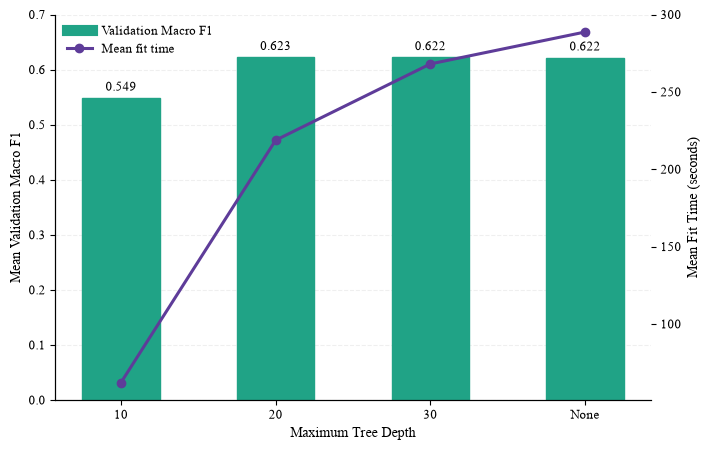

In [65]:
depth_results = pd.read_csv("forest_depth_results.csv", keep_default_na=False)

depth_values = ["10", "20", "30", "None"]

depth_f1 = []
depth_time = []

for value in depth_values:
    results = depth_results[depth_results["max_depth"].astype(str) == value]
    depth_f1.append(results["validation_f1"].mean())
    depth_time.append(results["fit_time"].mean())

x = np.arange(len(depth_values))

cmap = plt.get_cmap("viridis")
bar_color = cmap(0.58)
line_color = "#5E3C99"

fig, ax1 = plt.subplots(figsize=(7.2, 4.6))

bars = ax1.bar(x, depth_f1, width=0.5, color=bar_color, edgecolor=bar_color)

for i in range(len(depth_values)):
    ax1.text(
        x[i],
        depth_f1[i] + 0.008,
        f"{depth_f1[i]:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax1.set_xlabel("Maximum Tree Depth")
ax1.set_ylabel("Mean Validation Macro F1")
ax1.set_xticks(x)
ax1.set_xticklabels(depth_values)
ax1.set_ylim(0, 0.7)
ax1.grid(axis="y", linestyle="--", alpha=0.2)
ax1.set_axisbelow(True)

ax2 = ax1.twinx()
ax2.plot(x, depth_time, color=line_color, marker="o", linewidth=2.2, markersize=6)
ax2.set_ylabel("Mean Fit Time (seconds)")

bar_proxy = plt.Line2D([0], [0], color=bar_color, linewidth=8)
line_proxy = plt.Line2D([0], [0], color=line_color, marker="o", linewidth=2.2)

ax1.legend(
    [bar_proxy, line_proxy],
    ["Validation Macro F1", "Mean fit time"],
    loc="upper left",
    frameon=False,
    fontsize=9
)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax2.spines["top"].set_visible(False)

fig.tight_layout()
fig.savefig("forest_depth_performance.png", dpi=300, bbox_inches="tight")
plt.show()

In [26]:
weight_values = [None, "balanced", "balanced_subsample"]

results_file = Path("forest_weights_results.csv")
forest_weights_results = []

if results_file.exists():
    forest_weights_results = pd.read_csv(results_file, keep_default_na=False).to_dict("records")

depth_file = Path("forest_depth_results.csv")

if depth_file.exists():
    previous_results = pd.read_csv(depth_file, keep_default_na=False)

    for i in range(len(previous_results)):
        result = previous_results.iloc[i]

        if str(result["max_depth"]) != "20":
            continue

        completed = False

        for existing in forest_weights_results:
            if existing["outer_fold"] == result["outer_fold"] and existing["inner_fold"] == result["inner_fold"] and existing["class_weight"] == "balanced":
                completed = True
                break

        if not completed:
            forest_weights_results.append({
                "outer_fold": int(result["outer_fold"]),
                "inner_fold": int(result["inner_fold"]),
                "class_weight": "balanced",
                "validation_f1": result["validation_f1"],
                "fit_time": result["fit_time"]
            })

    pd.DataFrame(forest_weights_results).to_csv(results_file, index=False)

max_outer_folds = 5
max_inner_folds = 5

for outer_fold, (train_index, test_index) in enumerate(forest_outer_cv.split(X, y, groups=forest_group_ids), start=1):
    if outer_fold > max_outer_folds:
        break

    print(f"\nOuter Fold {outer_fold}/5", flush=True)

    X_outer = X.iloc[train_index]
    y_outer = y.iloc[train_index]
    groups_outer = forest_group_ids.iloc[train_index]

    for inner_fold, (inner_train_index, inner_val_index) in enumerate(forest_inner_cv.split(X_outer, y_outer, groups=groups_outer), start=1):
        if inner_fold > max_inner_folds:
            break

        completed_weights = []

        for result in forest_weights_results:
            if result["outer_fold"] == outer_fold and result["inner_fold"] == inner_fold:
                completed_weights.append(str(result["class_weight"]))

        completed = True

        for class_weight in weight_values:
            if str(class_weight) not in completed_weights:
                completed = False

        if completed:
            print(f"Inner Fold {inner_fold} already completed.")
            continue

        print(f"Inner Fold {inner_fold}/5", flush=True)

        X_train = X_outer.iloc[inner_train_index]
        X_val = X_outer.iloc[inner_val_index]

        y_train = y_outer.iloc[inner_train_index]
        y_val = y_outer.iloc[inner_val_index]

        preprocessor = clone(tree_preprocessor)

        X_train_processed = preprocessor.fit_transform(X_train)
        X_val_processed = preprocessor.transform(X_val)

        for class_weight in weight_values:
            weight_label = str(class_weight)

            if weight_label in completed_weights:
                continue

            forest = clone(forest_pipeline.named_steps["model"])
            forest.set_params(n_estimators=100, max_features=0.4, max_depth=20, class_weight=class_weight, warm_start=False, n_jobs=2)

            start = perf_counter()
            forest.fit(X_train_processed, y_train)
            fit_time = perf_counter() - start

            predictions = forest.predict(X_val_processed)
            macro_f1 = f1_score(y_val, predictions, average="macro")

            forest_weights_results.append({
                "outer_fold": outer_fold,
                "inner_fold": inner_fold,
                "class_weight": weight_label,
                "validation_f1": macro_f1,
                "fit_time": fit_time
            })

            pd.DataFrame(forest_weights_results).to_csv(results_file, index=False)

            print(f"Weight: {weight_label} | Macro F1: {macro_f1:.4f} | Time: {fit_time:.1f}s", flush=True)

forest_weights_results_df = pd.DataFrame(forest_weights_results)

forest_weights_summary = forest_weights_results_df.groupby("class_weight").agg(
    validation_f1_mean=("validation_f1", "mean"),
    validation_f1_std=("validation_f1", "std"),
    fit_time_mean=("fit_time", "mean"),
    fit_time_std=("fit_time", "std"),
    completed_fits=("validation_f1", "count")
)

display(forest_weights_summary.round(4))


Outer Fold 1/5
Inner Fold 1/5
Weight: None | Macro F1: 0.5887 | Time: 240.5s
Weight: balanced_subsample | Macro F1: 0.6236 | Time: 301.4s
Inner Fold 2/5
Weight: None | Macro F1: 0.5878 | Time: 268.6s
Weight: balanced_subsample | Macro F1: 0.6234 | Time: 298.2s
Inner Fold 3/5
Weight: None | Macro F1: 0.6001 | Time: 288.1s
Weight: balanced_subsample | Macro F1: 0.6306 | Time: 305.1s
Inner Fold 4/5
Weight: None | Macro F1: 0.5809 | Time: 260.8s
Weight: balanced_subsample | Macro F1: 0.6256 | Time: 288.2s
Inner Fold 5/5
Weight: None | Macro F1: 0.5884 | Time: 264.9s
Weight: balanced_subsample | Macro F1: 0.6310 | Time: 280.3s

Outer Fold 2/5
Inner Fold 1/5
Weight: None | Macro F1: 0.5824 | Time: 271.8s
Weight: balanced_subsample | Macro F1: 0.6215 | Time: 319.9s
Inner Fold 2/5
Weight: None | Macro F1: 0.5862 | Time: 269.9s
Weight: balanced_subsample | Macro F1: 0.6301 | Time: 301.3s
Inner Fold 3/5
Weight: None | Macro F1: 0.5922 | Time: 266.6s
Weight: balanced_subsample | Macro F1: 0.6250

,validation_f1_mean,validation_f1_std,fit_time_mean,fit_time_std,completed_fits
class_weight,,,,,
None,0.5906,0.0054,266.8881,30.1047,25
balanced,0.6226,0.0047,218.7686,9.2745,25
balanced_subsample,0.6285,0.0054,293.6193,24.5979,25


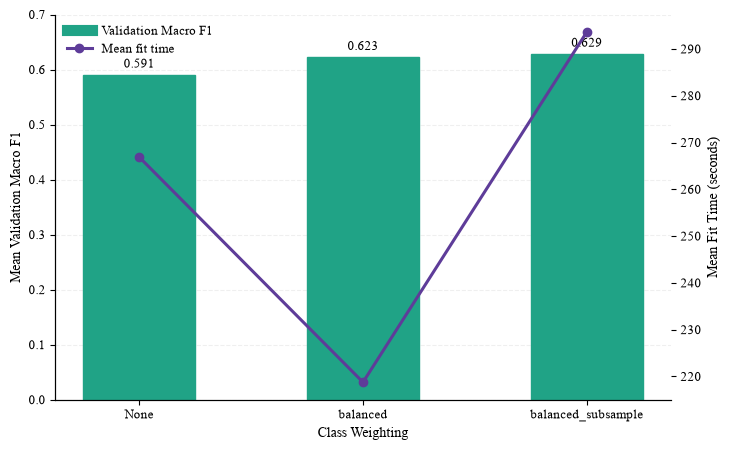

In [66]:
weight_results = pd.read_csv("forest_weights_results.csv", keep_default_na=False)

weight_values = ["None", "balanced", "balanced_subsample"]

weight_f1 = []
weight_time = []

for value in weight_values:
    results = weight_results[weight_results["class_weight"].astype(str) == value]
    weight_f1.append(results["validation_f1"].mean())
    weight_time.append(results["fit_time"].mean())

x = np.arange(len(weight_values))

cmap = plt.get_cmap("viridis")
bar_color = cmap(0.58)
line_color = "#5E3C99"

fig, ax1 = plt.subplots(figsize=(7.4, 4.6))

bars = ax1.bar(x, weight_f1, width=0.5, color=bar_color, edgecolor=bar_color)

for i in range(len(weight_values)):
    ax1.text(
        x[i],
        weight_f1[i] + 0.008,
        f"{weight_f1[i]:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax1.set_xlabel("Class Weighting")
ax1.set_ylabel("Mean Validation Macro F1")
ax1.set_xticks(x)
ax1.set_xticklabels(weight_values)
ax1.set_ylim(0, 0.7)
ax1.grid(axis="y", linestyle="--", alpha=0.2)
ax1.set_axisbelow(True)

ax2 = ax1.twinx()
ax2.plot(x, weight_time, color=line_color, marker="o", linewidth=2.2, markersize=6)
ax2.set_ylabel("Mean Fit Time (seconds)")

bar_proxy = plt.Line2D([0], [0], color=bar_color, linewidth=8)
line_proxy = plt.Line2D([0], [0], color=line_color, marker="o", linewidth=2.2)

ax1.legend(
    [bar_proxy, line_proxy],
    ["Validation Macro F1", "Mean fit time"],
    loc="upper left",
    frameon=False,
    fontsize=9
)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax2.spines["top"].set_visible(False)

fig.tight_layout()
fig.savefig("forest_weights_performance.png", dpi=300, bbox_inches="tight")
plt.show()

In [27]:
results_file = Path("forest_outer_results.csv")
forest_outer_results = []

if results_file.exists():
    forest_outer_results = pd.read_csv(results_file).to_dict("records")

for outer_fold, (train_index, test_index) in enumerate(forest_outer_cv.split(X, y, groups=forest_group_ids), start=1):
    predictions_file = Path(f"forest_predictions_fold_{outer_fold}.csv")

    completed = False

    for result in forest_outer_results:
        if int(result["outer_fold"]) == outer_fold and predictions_file.exists():
            completed = True
            break

    if completed:
        print(f"Outer Fold {outer_fold}/5 already completed.")
        continue

    print(f"\nOuter Fold {outer_fold}/5", flush=True)

    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    forest = clone(forest_pipeline)

    forest.set_params(
        model__n_estimators=100,
        model__max_features=0.4,
        model__max_depth=20,
        model__class_weight="balanced_subsample",
        model__n_jobs=2
    )

    start = perf_counter()
    forest.fit(X_train, y_train)
    fit_time = perf_counter() - start

    predictions = forest.predict(X_test)

    macro_f1 = f1_score(y_test, predictions, average="macro")
    mcc = matthews_corrcoef(y_test, predictions)
    accuracy = accuracy_score(y_test, predictions)

    fold_predictions = pd.DataFrame({
        "row_index": X_test.index,
        "actual": y_test.to_numpy(),
        "predicted": predictions
    })

    fold_predictions.to_csv(predictions_file, index=False)

    for result in forest_outer_results:
        if int(result["outer_fold"]) == outer_fold:
            forest_outer_results.remove(result)
            break

    forest_outer_results.append({
        "outer_fold": outer_fold,
        "macro_f1": macro_f1,
        "mcc": mcc,
        "accuracy": accuracy,
        "fit_time": fit_time
    })

    pd.DataFrame(forest_outer_results).to_csv(results_file, index=False)

    print(f"Macro F1: {macro_f1:.4f}", flush=True)
    print(f"MCC: {mcc:.4f}", flush=True)
    print(f"Accuracy: {accuracy:.4f}", flush=True)
    print(f"Training Time: {fit_time:.1f}s", flush=True)

forest_outer_results_df = pd.DataFrame(forest_outer_results)
forest_outer_results_df = forest_outer_results_df.sort_values("outer_fold")

print("\nFinal Random Forest Results")
display(forest_outer_results_df.round(4))

print("\nMean and Standard Deviation")
display(forest_outer_results_df[["macro_f1", "mcc", "accuracy"]].agg(["mean", "std"]).round(4))

all_predictions = []

for outer_fold in range(1, 6):
    predictions_file = Path(f"forest_predictions_fold_{outer_fold}.csv")

    if predictions_file.exists():
        fold_predictions = pd.read_csv(predictions_file)
        all_predictions.append(fold_predictions)

if len(all_predictions) == 5:
    forest_predictions_df = pd.concat(all_predictions, ignore_index=True)
    forest_predictions_df = forest_predictions_df.sort_values("row_index")

    forest_predictions_df.to_csv("forest_oof_predictions.csv", index=False)

    forest_oof_predictions = forest_predictions_df.set_index("row_index")["predicted"]
    forest_oof_predictions = forest_oof_predictions.reindex(X.index)
    
    print("\nAll outer-fold predictions saved.")



Outer Fold 1/5
Macro F1: 0.6418
MCC: 0.7644
Accuracy: 0.8102
Training Time: 407.5s

Outer Fold 2/5
Macro F1: 0.6396
MCC: 0.7573
Accuracy: 0.8051
Training Time: 517.8s

Outer Fold 3/5
Macro F1: 0.6295
MCC: 0.7610
Accuracy: 0.8079
Training Time: 458.5s

Outer Fold 4/5
Macro F1: 0.6333
MCC: 0.7600
Accuracy: 0.8067
Training Time: 430.5s

Outer Fold 5/5
Macro F1: 0.6298
MCC: 0.7574
Accuracy: 0.8050
Training Time: 426.2s

Final Random Forest Results


,outer_fold,macro_f1,mcc,accuracy,fit_time
0,1,0.6418,0.7644,0.8102,407.4998
1,2,0.6396,0.7573,0.8051,517.7555
2,3,0.6295,0.7610,0.8079,458.5177
3,4,0.6333,0.7600,0.8067,430.4764
4,5,0.6298,0.7574,0.8050,426.2249



Mean and Standard Deviation


,macro_f1,mcc,accuracy
mean,0.6348,0.7600,0.8070
std,0.0056,0.0029,0.0021



All outer-fold predictions saved.


In [31]:
forest_predictions = pd.read_csv("forest_oof_predictions.csv")

forest_predictions = forest_predictions.set_index("row_index")
forest_predictions = forest_predictions.reindex(y.index)

if forest_predictions["predicted"].isna().any():
    raise ValueError("Some Random Forest predictions are missing.")

if not np.array_equal(forest_predictions["actual"].to_numpy(), y.to_numpy()):
    raise ValueError("Random Forest predictions do not match the original dataset.")

forest_oof_predictions = forest_predictions["predicted"].to_numpy()

class_labels = np.sort(y.unique())

print("Random Forest predictions loaded:", len(forest_oof_predictions))


Random Forest predictions loaded: 257673


In [32]:
models = [
    ("kNN", "knn_outer_results.csv"),
    ("Classification Tree", "tree_outer_results.csv"),
    ("Random Forest", "forest_outer_results.csv")
]

performance_results = []

for model_name, file_name in models:
    results = pd.read_csv(file_name)

    performance_results.append({
        "Model": model_name,
        "Macro F1": f"{results['macro_f1'].mean():.4f} ± {results['macro_f1'].std():.4f}",
        "MCC": f"{results['mcc'].mean():.4f} ± {results['mcc'].std():.4f}",
        "Accuracy": f"{results['accuracy'].mean():.4f} ± {results['accuracy'].std():.4f}"
    })

final_performance = pd.DataFrame(performance_results)

display(final_performance)

final_performance.to_csv("final_model_comparison.csv", index=False)
final_performance.to_latex("final_model_comparison.tex", index=False)


,Model,Macro F1,MCC,Accuracy
0,kNN,0.5181 ± 0.0186,0.7408 ± 0.0095,0.8011 ± 0.0077
1,Classification Tree,0.5967 ± 0.0064,0.7167 ± 0.0024,0.7700 ± 0.0023
2,Random Forest,0.6348 ± 0.0056,0.7600 ± 0.0029,0.8070 ± 0.0021


In [70]:
tuning_settings = [
    ("Number of Trees", "forest_trees_warmstart.csv", "n_estimators", 100),
    ("Maximum Features", "forest_features_100_results.csv", "max_features", 0.4),
    ("Maximum Depth", "forest_depth_results.csv", "max_depth", 20),
    ("Class Weight", "forest_weights_results.csv", "class_weight", "balanced_subsample")
]

tuning_results = []

for parameter, file_name, column, selected_value in tuning_settings:
    results = pd.read_csv(file_name, keep_default_na=False)

    selected_results = results[
        results[column].astype(str) == str(selected_value)
    ]

    tuning_results.append({
        "Parameter": parameter,
        "Selected Value": selected_value,
        "Validation Macro F1": selected_results["validation_f1"].mean()
    })

tuning_table = pd.DataFrame(tuning_results)

display(tuning_table.round(4))

tuning_table.to_csv("forest_tuning_summary.csv", index=False)
tuning_table.to_latex("forest_tuning_summary.tex", index=False)

,Parameter,Selected Value,Validation Macro F1
0,Number of Trees,100,0.5809
1,Maximum Features,0.4,0.6226
2,Maximum Depth,20,0.6226
3,Class Weight,balanced_subsample,0.6285


In [71]:
per_class_results = pd.read_csv("per_class_results.csv")

forest_precision, forest_recall, forest_f1, forest_support = precision_recall_fscore_support(
    y,
    forest_oof_predictions,
    labels=class_labels,
    zero_division=0
)

per_class_results["Forest Precision"] = forest_precision
per_class_results["Forest Recall"] = forest_recall
per_class_results["Forest F1"] = forest_f1

display(per_class_results.round(4))

per_class_results.to_csv("all_models_per_class_results.csv", index=False)
per_class_results.round(4).to_latex(
    "all_models_per_class_results.tex",
    index=False
)

,Class,Support,kNN Precision,kNN Recall,kNN F1,Tree Precision,Tree Recall,Tree F1,Forest Precision,Forest Recall,Forest F1
0,0,93000,0.8829,0.9251,0.9035,0.9485,0.8165,0.8776,0.9516,0.8608,0.9039
1,1,13987,0.7495,0.7107,0.7295,0.8469,0.7989,0.8222,0.8876,0.7980,0.8404
2,2,2329,0.6085,0.0494,0.0913,0.0890,0.4826,0.1502,0.1458,0.3422,0.2045
3,3,16353,0.3755,0.4497,0.4092,0.3679,0.6085,0.4586,0.3736,0.7729,0.5037
4,4,44525,0.6692,0.7284,0.6975,0.8627,0.5176,0.6470,0.8626,0.5759,0.6907
5,5,2677,0.5943,0.0624,0.1129,0.0983,0.1924,0.1301,0.1772,0.0960,0.1245
6,6,24246,0.6432,0.4995,0.5623,0.5462,0.7269,0.6237,0.6005,0.7509,0.6674
7,7,174,0.5833,0.1609,0.2523,0.5885,0.7069,0.6423,0.6984,0.7586,0.7273
8,8,1511,0.3834,0.4547,0.4160,0.5584,0.7181,0.6283,0.6172,0.7929,0.6941
9,9,58871,0.9959,0.9774,0.9865,0.9908,0.9825,0.9866,0.9964,0.9826,0.9894


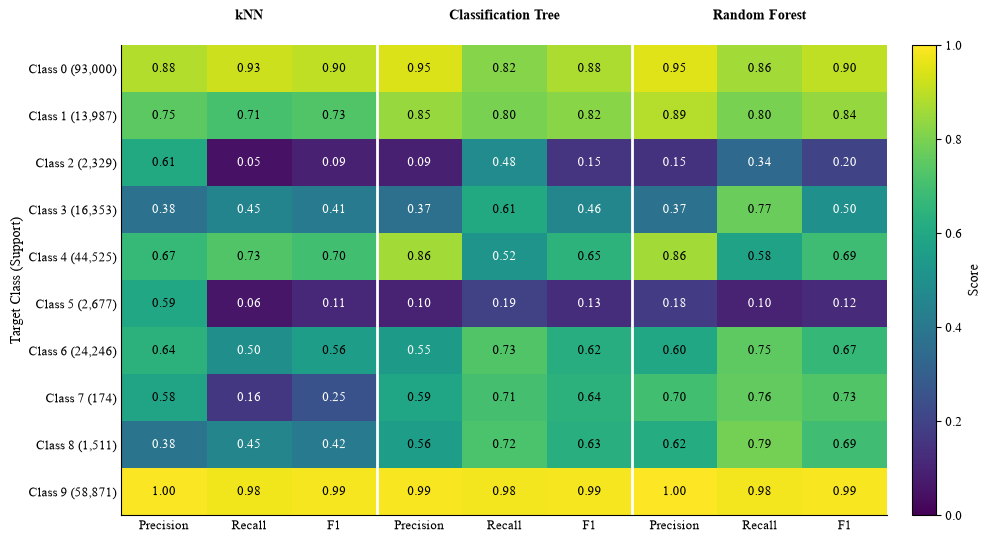

In [67]:
per_class_sorted = per_class_results.sort_values("Class")

metric_columns = [
    "kNN Precision", "kNN Recall", "kNN F1",
    "Tree Precision", "Tree Recall", "Tree F1",
    "Forest Precision", "Forest Recall", "Forest F1"
]

metrics = per_class_sorted[metric_columns].values

labels = []

for _, result in per_class_sorted.iterrows():
    class_number = int(result["Class"])
    support = int(result["Support"])

    labels.append(f"Class {class_number} ({support:,})")

fig, ax = plt.subplots(figsize=(10, 5.5))

image = ax.imshow(
    metrics,
    cmap="viridis",
    aspect="auto",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(9))
ax.set_xticklabels([
    "Precision", "Recall", "F1",
    "Precision", "Recall", "F1",
    "Precision", "Recall", "F1"
])

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)

ax.set_ylabel("Target Class (Support)")

ax.tick_params(axis="both", length=0)

ax.axvline(2.5, color="white", linewidth=2)
ax.axvline(5.5, color="white", linewidth=2)

for row in range(metrics.shape[0]):
    for column in range(metrics.shape[1]):
        score = metrics[row, column]

        text_color = "white"

        if score >= 0.55:
            text_color = "black"

        ax.text(
            column,
            row,
            f"{score:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=9
        )

ax.text(1, 1.055, "kNN", transform=ax.get_xaxis_transform(), ha="center", fontweight="bold")
ax.text(4, 1.055, "Classification Tree", transform=ax.get_xaxis_transform(), ha="center", fontweight="bold")
ax.text(7, 1.055, "Random Forest", transform=ax.get_xaxis_transform(), ha="center", fontweight="bold")

fig.colorbar(image, ax=ax, label="Score", fraction=0.035, pad=0.03)

fig.tight_layout()
fig.savefig("all_models_per_class_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

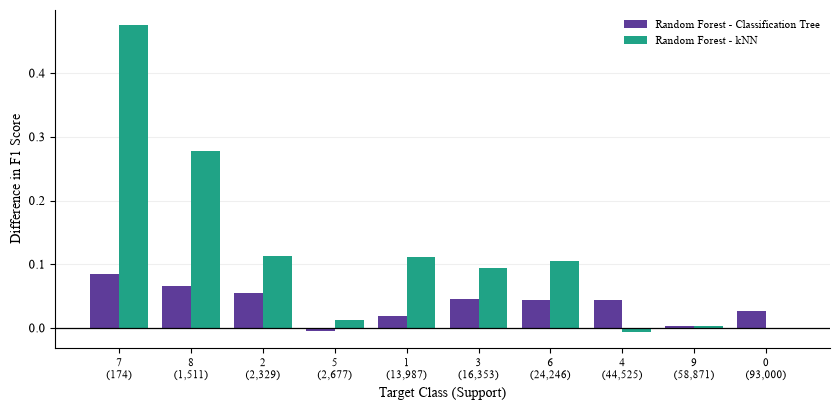

In [69]:

class_comparison = per_class_results.sort_values("Support")

forest_vs_tree = class_comparison["Forest F1"] - class_comparison["Tree F1"]
forest_vs_knn = class_comparison["Forest F1"] - class_comparison["kNN F1"]

positions = np.arange(len(class_comparison))

labels = []

for _, result in class_comparison.iterrows():
    class_number = int(result["Class"])
    support = int(result["Support"])

    labels.append(f"{class_number}\n({support:,})")

cmap = plt.get_cmap("viridis")
green = cmap(0.58)
purple = "#5E3C99"

fig, ax = plt.subplots(figsize=(8.5, 4.2))

ax.bar(
    positions - 0.2,
    forest_vs_tree,
    width=0.4,
    color=purple,
    label="Random Forest - Classification Tree"
)

ax.bar(
    positions + 0.2,
    forest_vs_knn,
    width=0.4,
    color=green,
    label="Random Forest - kNN"
)

ax.axhline(0, color="black", linewidth=0.9)

ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=8)

ax.set_xlabel("Target Class (Support)")
ax.set_ylabel("Difference in F1 Score")

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig("forest_f1_improvement_by_class.png", dpi=300, bbox_inches="tight")
plt.show()
